# Fluid Dynamics

This notebook presents partial differential equations (PDE) that can be found in Computational Fluid Dynamics (CFD). 
Those PDEs are great to test quantum algorithms because they are increasingly difficult to solve and have theoretical solutions. 
For each of them, a small python code is provided to solve it and compare a numerical scheme with the theoretical solution. 

> **Objective.** Simulate the **Navier–Stokes equations (NSE)** in 3D — the ideal, ambitious
> target. The Burgers, advection and diffusion equations are reachable stepping stones towards
> it.

## Environment

```bash
pip install numpy matplotlib
```

This notebook needs only `numpy` and `matplotlib`. The imports and the finite-difference toolbox
are in the first code cell below. All the numerical results are **classical baselines** — they are
what your own solution should reproduce.

## The equations, from easy to hard

All equations below live in a domain $\Omega \subset \mathbb{R}^d$ ($d=1,2,3$) and describe the
evolution of a quantity $u(x,t)$ (a velocity component, temperature, concentration, ...).

| # | Equation | Linearity | Type | Difficulty |
|---|----------|-----------|------|-----------|
| 1 | Diffusion | linear | parabolic | ★ |
| 2 | Advection | linear | hyperbolic | ★ |
| 3 | Burgers | nonlinear | mixed | ★★ |
| 4 | Navier–Stokes | nonlinear | mixed, coupled | ★★★ |

We now define each equation and give a numerical baseline.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# 1D finite-difference "toolbox" used throughout this subject.
# These are CLASSICAL numerical baselines: your own solution should reproduce them.
# ---------------------------------------------------------------------------

def solve_diffusion(u0, nu, dx, dt, n_steps):
    """Explicit FTCS scheme for u_t = nu u_xx (edges held at boundary values).

    u_i^{n+1} = u_i^n + r (u_{i+1} - 2 u_i + u_{i-1}),  r = nu dt/dx^2.
    Stable only if r <= 1/2 (the diffusive CFL condition).
    """
    r = nu * dt / dx**2
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = u[1:-1] + r * (u[2:] - 2*u[1:-1] + u[:-2])
    return u

def solve_advection(u0, c, dx, dt, n_steps):
    """Upwind scheme for u_t + c u_x = 0 (assumes c > 0).

    u_i^{n+1} = u_i^n - C (u_i^n - u_{i-1}^n),  C = c dt/dx.
    First-order, stable if C <= 1, but adds numerical diffusion.
    """
    C = c * dt / dx
    u = u0.copy()
    for _ in range(n_steps):
        u[1:] = u[1:] - C * (u[1:] - u[:-1])
    return u

def burgers_inviscid(u0, dx, dt, n_steps):
    """Conservative upwind flux for inviscid Burgers u_t + u u_x = 0.

    Flux F(u) = u^2/2; upwind (for u>0) gives F_{i+1/2} = F(u_i).
    Conservative schemes conserve the total mass even across a shock.
    """
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = u[1:-1] - dt/dx * (0.5*u[1:-1]**2 - 0.5*u[:-2]**2)
    return u

def burgers_direct(u0, nu, dx, dt, n_steps):
    """Upwind convective flux + central diffusion for viscous Burgers."""
    u = u0.copy()
    for _ in range(n_steps):
        u[1:-1] = (u[1:-1]
                   - dt/dx * (0.5*u[1:-1]**2 - 0.5*u[:-2]**2)   # nonlinear flux
                   + nu*dt/dx**2 * (u[2:] - 2*u[1:-1] + u[:-2])) # diffusion
    return u

def exact_diffusion_gaussian(x, t, nu, sigma):
    """Exact solution of u_t = nu u_xx from a Gaussian initial condition."""
    return sigma/np.sqrt(sigma**2 + 2*nu*t) * np.exp(-x**2/(2*(sigma**2 + 2*nu*t)))

def exact_advection(x, t, c, sigma):
    """Exact solution of u_t + c u_x = 0 from a Gaussian initial condition."""
    return np.exp(-(x - c*t)**2/(2*sigma**2))

## 1. Advection (transport) equation

$$\frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = 0, \qquad c \in \mathbb{R} \text{ constant}.$$

This is the simplest **linear hyperbolic** PDE: $u$ is simply carried along at velocity $c$
without changing shape. The solution is a pure translation along the characteristics
$x - c t = \text{const}$:

$$u(x,t) = u_0(x - c t).$$

**Key facts.**
- *Hyperbolic*: information travels at finite speed $c$ along characteristics.
- *No smoothing*: the initial profile is preserved exactly.
- *CFL condition*: any explicit scheme needs $|c|\,\Delta t / \Delta x \le 1$ for stability.
- *Upwind scheme* (for $c>0$): $u_i^{n+1} = u_i^n - C\,(u_i^n - u_{i-1}^n)$, $C = c\Delta t/\Delta x$.
  It is stable but **first-order**, hence adds numerical diffusion.

It is the *transport* part of NSE, where here the advection velocity $c$ is a given constant.
Note in the plot below that the first-order upwind scheme slightly smears the Gaussian
(numerical diffusion) while the exact solution translates it perfectly.

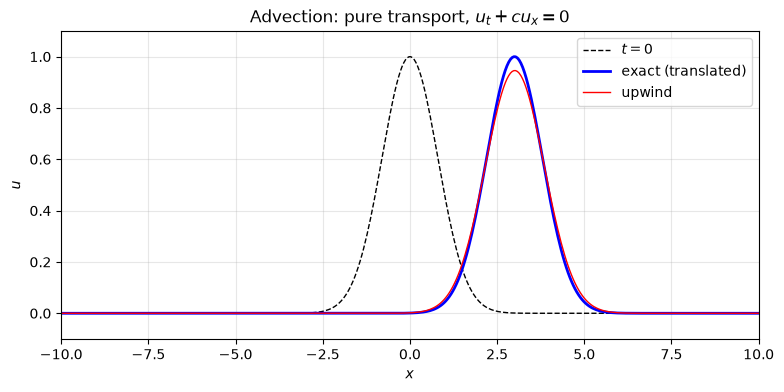

In [3]:
L, N = 20.0, 400
x = np.linspace(-L/2, L/2, N)
dx = x[1] - x[0]
c, sigma, t = 1.0, 0.8, 3.0
u0 = np.exp(-x**2/(2*sigma**2))

dt = 0.5*dx/c                       # CFL = 0.5 < 1  -> stable
u_num = solve_advection(u0, c, dx, dt, int(round(t/dt)))
u_exact = exact_advection(x, t, c, sigma)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, u0, 'k--', lw=1, label=r'$t=0$')
ax.plot(x, u_exact, 'b-', lw=2, label='exact (translated)')
ax.plot(x, u_num, 'r-', lw=1, label='upwind')
ax.set_xlim(-L/2, L/2); ax.set_ylim(-0.1, 1.1)
ax.legend(); ax.set_title('Advection: pure transport, $u_t + c u_x = 0$')
ax.grid(alpha=0.3); ax.set_xlabel('$x$'); ax.set_ylabel('$u$')
plt.show()

### A note on numerical diffusion

The upwind solution is slightly wider than the exact translated Gaussian. This is **numerical
diffusion**: the first-order upwind scheme has a truncation error that behaves like an *extra*
diffusion of size $\tfrac12 c\,\Delta x\,(1 - C)$, where $C = c\Delta t/\Delta x$ is the Courant
number. So even though the equation is a *pure* advection (no physical diffusion), the scheme
smooths the profile as if there were one.

- It is a **scheme artifact**, not physics: it disappears as $\Delta x \to 0$ (finer grid).
- It is the price of **stability**: upwind is stable but only first-order accurate.
- It is *not* the same as the physical diffusivity $\nu$ of the diffusion equation: it is an
  error term that depends on the grid.

To reduce it: refine the grid, or use a higher-order scheme (e.g. Lax–Wendroff, or a spectral
method). The same phenomenon appears in the LBM notebook.

## 2. Diffusion (heat) equation

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial x^2}, \qquad \nu > 0.$$

This is the simplest **linear parabolic** PDE ($\nu$ = diffusivity / kinematic viscosity).

**Key facts.**
- *Parabolic*: instantaneous smoothing. $u$ becomes $C^\infty$ for $t>0$ even if $u_0$ is rough.
- *Maximum principle*: $\min u_0 \le u \le \max u_0$.
- *Fundamental solution* (heat kernel) on the line:
  $$G(x,t) = \frac{1}{\sqrt{4\pi\nu t}}\,\exp\!\left(-\frac{x^2}{4\nu t}\right),
  \qquad u(x,t) = (G * u_0)(x,t).$$
- *Explicit FTCS scheme*: $u_i^{n+1} = u_i^n + r\,(u_{i+1}^n - 2u_i^n + u_{i-1}^n)$, with
  $r = \nu\Delta t/\Delta x^2$, stable iff $r \le 1/2$.
- *In Fourier space* $\hat u(k,t) = \hat u_0(k)\,e^{-\nu k^2 t}$: high wavenumbers decay fastest,
  so diffusion is a **low-pass filter**.

It is the *dissipative* (viscous) part of NSE: it smooths the flow and damps the smallest
scales.

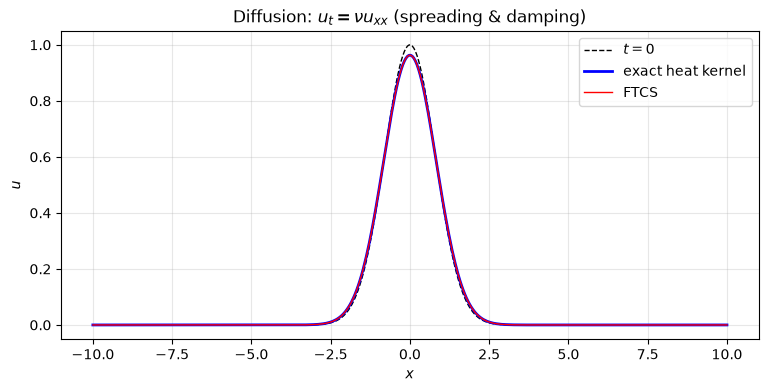

In [4]:
L, N = 20.0, 400
x = np.linspace(-L/2, L/2, N)
dx = x[1] - x[0]
nu, sigma, t = 0.05, 0.8, 0.5
u0 = np.exp(-x**2/(2*sigma**2))

dt = 0.4*dx**2/nu                     # r = 0.4 <= 1/2  -> stable
u_num = solve_diffusion(u0, nu, dx, dt, int(round(t/dt)))
u_exact = exact_diffusion_gaussian(x, t, nu, sigma)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, u0, 'k--', lw=1, label=r'$t=0$')
ax.plot(x, u_exact, 'b-', lw=2, label='exact heat kernel')
ax.plot(x, u_num, 'r-', lw=1, label='FTCS')
ax.legend(); ax.set_title('Diffusion: $u_t = \\nu u_{xx}$ (spreading & damping)')
ax.grid(alpha=0.3); ax.set_xlabel('$x$'); ax.set_ylabel('$u$')
plt.show()

## 3. Burgers equation

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}.$$

Burgers is the simplest PDE combining **nonlinearity** (the $u\,u_x$ term) and **diffusion**. The
term $u\,u_x$ is the 1D version of the convective term $(\mathbf{u}\cdot\nabla)\mathbf{u}$ of NSE:
the field advects *itself*. It is a standard playground for the phenomena that make fluid dynamics
hard.

**Shock formation.** Since the advection velocity is the field itself, the characteristics
$x = x_0 + u_0(x_0)\,t$ travel at different speeds depending on the local value of $u$. Where the
initial profile is decreasing, the characteristics converge and eventually cross, and the solution
develops a **shock** (a near-discontinuity) in finite time. A smooth initial condition therefore
becomes discontinuous *spontaneously* — this is the nonlinearity at work, and it is the central
phenomenon of this subject.

**Two regimes.**
- **Inviscid** ($\nu = 0$): the shock forms and persists; the solution ceases to be smooth and
  must be understood in a *weak* sense.
- **Viscous** ($\nu > 0$): diffusion regularises the shock into a thin front of width
  $\mathcal{O}(\nu)$, and the solution stays smooth.

The plots below evolve the same smooth (Gaussian) initial condition with a direct conservative
finite-volume scheme: the viscous case steepens but stays smooth, while the inviscid case forms a
shock.

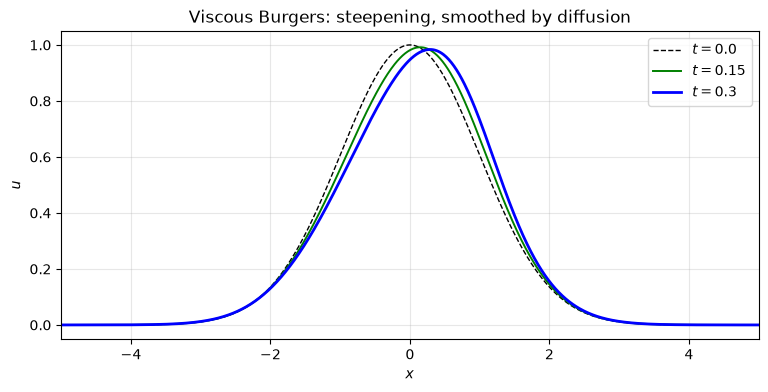

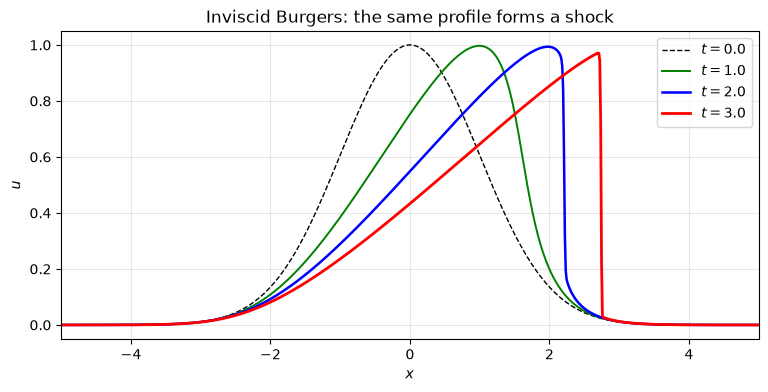

In [5]:
# (a) Viscous Burgers: steepening, but diffusion keeps the solution smooth
L, N = 10.0, 800
x = np.linspace(-L/2, L/2, N)
dx = x[1] - x[0]
nu, sigma = 0.05, 1.0
u0 = np.exp(-x**2/(2*sigma**2))          # same smooth initial condition in both plots
dt = 0.4*dx**2/nu                        # diffusive stability limit

def viscous_at(t):
    return burgers_direct(u0, nu, dx, dt, int(round(t/dt)))

fig, ax = plt.subplots(figsize=(9, 4))
for t, c, lw in [(0.0, 'k--', 1.0), (0.15, 'g-', 1.4), (0.3, 'b-', 2.0)]:
    ax.plot(x, viscous_at(t), c, lw=lw, label=f'$t={t}$')
ax.legend(); ax.set_title('Viscous Burgers: steepening, smoothed by diffusion')
ax.grid(alpha=0.3); ax.set_xlim(-5, 5); ax.set_xlabel('$x$'); ax.set_ylabel('$u$')
plt.show()

# (b) Inviscid Burgers: the SAME profile spontaneously forms a shock
dt2 = 0.5*dx                            # CFL < 1
def inviscid_at(t):
    return burgers_inviscid(u0, dx, dt2, int(round(t/dt2)))

fig, ax = plt.subplots(figsize=(9, 4))
for t, c, lw in [(0.0, 'k--', 1.0), (1.0, 'g-', 1.4), (2.0, 'b-', 1.8), (3.0, 'r-', 2.0)]:
    ax.plot(x, inviscid_at(t), c, lw=lw, label=f'$t={t}$')
ax.legend(); ax.set_title('Inviscid Burgers: the same profile forms a shock')
ax.grid(alpha=0.3); ax.set_xlim(-5, 5); ax.set_xlabel('$x$'); ax.set_ylabel('$u$')
plt.show()

## 4. Navier–Stokes equations (the ideal objective)

For an incompressible Newtonian fluid of constant density $\rho$ and kinematic viscosity $\nu$,
in $\Omega \subset \mathbb{R}^3$:

$$\frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u}\cdot\nabla)\,\mathbf{u}
= -\frac{1}{\rho}\nabla p + \nu\,\nabla^2\mathbf{u} + \mathbf{f},
\qquad \nabla\cdot\mathbf{u} = 0.$$

$\mathbf{u}(\mathbf{x},t)\in\mathbb{R}^3$ is the velocity field, $p$ the pressure, and
$\mathbf{f}$ a body force. The incompressibility constraint $\nabla\cdot\mathbf{u}=0$ is what
makes NSE **coupled** and **non-local**: pressure is not a dynamical variable but a Lagrange
multiplier that instantaneously enforces the constraint.

**Key features.**
- **Nonlinearity**: the convective term $(\mathbf{u}\cdot\nabla)\mathbf{u}$ is quadratic — the
  same nonlinearity as in Burgers, but coupling the three velocity components.
- **Coupling & non-locality**: pressure couples all components through a Poisson equation
  $\nabla^2 p = -\rho\,\nabla\cdot[(\mathbf{u}\cdot\nabla)\mathbf{u}]$.
- **Reynolds number** $Re = UL/\nu$: at large $Re$ the flow becomes **turbulent**, with a huge
  range of spatial and temporal scales, and the classical direct simulation cost grows roughly
  like $Re^{9/4}$.

## References

**PDEs & numerics**
- L. N. Trefethen, *Finite Difference and Spectral Methods for Ordinary and Partial Differential
  Equations* (unpublished book, freely available).
- R. J. LeVeque, *Numerical Methods for Conservation Laws*, 2nd ed., Birkhäuser, 1992.

**Fluid dynamics**
- A. J. Chorin, J. E. Marsden, *A Mathematical Introduction to Fluid Mechanics*, 3rd ed.,
  Springer, 1993.
- L. D. Landau, E. M. Lifshitz, *Fluid Mechanics*, Pergamon, 1987.

**Nonlinear waves & conservation laws**
- G. B. Whitham, *Linear and Nonlinear Waves*, Wiley, 1974.